### Tabulation impact of bombs

Comparison between DST and SDST to see impact of bombs on P values.

Three profiles:
- keep
- alternate (treasure big, time big, treasure small, time small)
- prioritize treasure (big, big, small, small)

10 seeds per profile per env (60 total) with same randomness.

In [11]:
from collections import defaultdict
from dataclasses import replace
from datetime import datetime
from pathlib import Path
import csv
import json
import pickle
import sys

import matplotlib.pyplot as plt
import numpy as np

from xmorl.config import load_config
from xmorl.envs.factory import make_env
from xmorl.evaluation import evaluate
from xmorl.logging import RunLogger
from xmorl.training import FeedbackChoice, TrainingCheckpoint, train
from xmorl.utils import obs_to_state, reset_env_with_seed


PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "pyproject.toml").is_file():
    raise RuntimeError("Start Jupyter from the XMORL project root")
source_directory = str(PROJECT_ROOT / "src")
if source_directory not in sys.path:
    sys.path.insert(0, source_directory)

ENVIRONMENTS = {
    "DST": load_config(PROJECT_ROOT / "configs" / "dst.yaml"),
    "SDST": load_config(PROJECT_ROOT / "configs" / "sdst.yaml"),
}
PROFILES = {
    "keep": (
        FeedbackChoice(),
        FeedbackChoice(),
        FeedbackChoice(),
    ),
    "alternate": (
        FeedbackChoice("treasure", 0, "big"),
        FeedbackChoice("time", 1, "big"),
        FeedbackChoice("treasure", 0, "small"),
        FeedbackChoice("time", 1, "small"),
    ),
    "treasure": (
        FeedbackChoice("treasure", 0, "big"),
        FeedbackChoice("treasure", 0, "big"),
        FeedbackChoice("treasure", 0, "small"),
        FeedbackChoice("treasure", 0, "small"),
    ),
}

REPETITION_SEEDS = tuple(range(10))
EXPERIMENT_ROOT = (
    PROJECT_ROOT
    / "runs"
    / "notebook_comparison"
    / datetime.now().strftime("%Y%m%d-%H%M%S")
)

EXPERIMENT_ROOT.mkdir(parents=True, exist_ok=False)
print(f"Results will be saved in: {EXPERIMENT_ROOT}")

Results will be saved in: C:\Users\nicol\Documents\GitHub\XMORL\runs\notebook_comparison\20260820-131642


In [12]:
class AutomatedFeedback:
    def __init__(self, config, choices, environment_name, profile_name, repetition):
        self.config = config
        self.choices = choices
        self.environment_name = environment_name
        self.profile_name = profile_name
        self.repetition = repetition
        self.validation_rows = []

    def __call__(self, checkpoint: TrainingCheckpoint) -> FeedbackChoice:
        settings = self.config.evaluation
        seeds = range(
            settings.checkpoint_seed_start,
            settings.checkpoint_seed_start + settings.checkpoint_episodes,
        )
        _, summary = evaluate(
            self.config.environment,
            checkpoint.model,
            checkpoint.weights,
            seeds,
            settings.max_steps,
        )
        self.validation_rows.append({
            "environment": self.environment_name,
            "profile": self.profile_name,
            "repetition": self.repetition,
            "training_seed": self.config.training.seed,
            "feedback_number": checkpoint.feedback_number,
            "episode": checkpoint.episode,
            "weight_treasure": checkpoint.weights[0],
            "weight_time": checkpoint.weights[1],
            "mean_return_scalar": summary["mean_return_scalar"],
            "mean_return_treasure": summary["mean_return_vec"][0],
            "mean_return_time": summary["mean_return_vec"][1],
            "success_rate": summary["success_rate"],
            "explosion_rate": summary["explosion_rate"],
            "timeout_rate": summary["timeout_rate"],
            "mean_length": summary["mean_length"],
        })
        return self.choices[checkpoint.feedback_number - 1]

def write_csv(path, rows):
    if not rows:
        return
    with path.open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

def p_value_rows(model, environment_name, profile_name, repetition, training_seed):
    rows = []
    for state in sorted(model.p, key=repr):
        objective_q = model.objective_q[state]
        for action, p_value in enumerate(model.p[state]):
            visits = int(model.visits[state][action])
            if visits == 0:
                continue
            rows.append({
                "environment": environment_name,
                "profile": profile_name,
                "repetition": repetition,
                "training_seed": training_seed,
                "state": json.dumps(state),
                "action": action,
                "p_value": float(p_value),
                "visits": visits,
                "scalar_q": float(model.q[state][action]),
                "objective_q_treasure": float(objective_q[action, 0]),
                "objective_q_time": float(objective_q[action, 1]),
            })
    return rows

def initial_state_p_rows(config, model, environment_name, profile_name, repetition):
    env = make_env(config.environment)
    try:
        observation, _ = reset_env_with_seed(env, config.training.seed)
        state = obs_to_state(observation)
    finally:
        env.close()
    p_values = model.p.get(state, np.zeros(model.num_actions))
    return [
        {
            "environment": environment_name,
            "profile": profile_name,
            "repetition": repetition,
            "training_seed": config.training.seed,
            "state": json.dumps(state),
            "action": action,
            "action_name": config.environment.action_names.get(action, str(action)),
            "p_value": float(value),
        }
        for action, value in enumerate(p_values)
    ]

def matched_config(base_config, environment_name, profile_name, repetition, seed):
    checkpoint_offset = repetition * base_config.evaluation.checkpoint_episodes
    final_offset = repetition * base_config.evaluation.final_episodes
    run_name = f"{environment_name.lower()}__{profile_name}__run_{repetition + 1:02d}"
    return replace(
        base_config,
        training=replace(
            base_config.training,
            seed=seed,
            utility_weights=(0.5, 0.5),
            progress_every=0,
        ),
        feedback=replace(
            base_config.feedback,
            enabled=True,
            num_moments=3,
            episodes=None,
        ),
        evaluation=replace(
            base_config.evaluation,
            checkpoint_seed_start=(
                base_config.evaluation.checkpoint_seed_start + checkpoint_offset
            ),
            final_seed_start=base_config.evaluation.final_seed_start + final_offset,
        ),
        logging=replace(
            base_config.logging,
            output_dir=str(EXPERIMENT_ROOT),
            run_name=run_name,
            wandb_enabled=False,
            wandb_mode="disabled",
        ),
        plotting=replace(base_config.plotting, enabled=False, show=False),
        gui=replace(base_config.gui, enabled=False),
    )

def run_once(base_config, environment_name, profile_name, choices, repetition, seed):
    config = matched_config(
        base_config, environment_name, profile_name, repetition, seed
    )
    feedback = AutomatedFeedback(
        config, choices, environment_name, profile_name, repetition
    )
    with RunLogger(config) as logger:
        result = train(
            config,
            logger,
            feedback_provider=feedback,
            segment_saver=logger.save_training_segment,
        )
        settings = config.evaluation
        final_seeds = range(
            settings.final_seed_start,
            settings.final_seed_start + settings.final_episodes,
        )
        _, summary = evaluate(
            config.environment,
            result.model,
            result.final_weights,
            final_seeds,
            settings.max_steps,
        )
        logger.save_results(result, summary)
        logger.write_json("validation_history.json", feedback.validation_rows)
        logger.write_json("profile.json", {
            "environment": environment_name,
            "profile": profile_name,
            "repetition": repetition,
            "training_seed": seed,
            "choices": [choice.__dict__ for choice in choices],
        })
        with (logger.run_dir / "model.pkl").open("wb") as handle:
            pickle.dump(result.model, handle, protocol=pickle.HIGHEST_PROTOCOL)
        run_p_rows = p_value_rows(
            result.model, environment_name, profile_name, repetition, seed
        )
        write_csv(logger.run_dir / "p_values.csv", run_p_rows)
        initial_rows = initial_state_p_rows(
            config, result.model, environment_name, profile_name, repetition
        )
        summary_row = {
            "environment": environment_name,
            "profile": profile_name,
            "repetition": repetition,
            "training_seed": seed,
            "final_weight_treasure": result.final_weights[0],
            "final_weight_time": result.final_weights[1],
            "mean_return_scalar": summary["mean_return_scalar"],
            "std_return_scalar": summary["std_return_scalar"],
            "mean_return_treasure": summary["mean_return_vec"][0],
            "mean_return_time": summary["mean_return_vec"][1],
            "success_rate": summary["success_rate"],
            "explosion_rate": summary["explosion_rate"],
            "timeout_rate": summary["timeout_rate"],
            "mean_length": summary["mean_length"],
            "run_directory": str(logger.run_dir.resolve()),
        }
    return summary_row, run_p_rows, initial_rows, feedback.validation_rows

In [13]:
summary_rows = []
all_p_rows = []
initial_p_rows = []
validation_rows = []
total_runs = len(ENVIRONMENTS) * len(PROFILES) * len(REPETITION_SEEDS)
completed = 0

for repetition, seed in enumerate(REPETITION_SEEDS):
    for profile_name, choices in PROFILES.items():
        for environment_name, base_config in ENVIRONMENTS.items():
            completed += 1
            print(
                f"[{completed:02d}/{total_runs}] {environment_name} / "
                f"{profile_name} / seed {seed}"
            )
            summary, p_rows, initial_rows, checkpoint_rows = run_once(
                base_config,
                environment_name,
                profile_name,
                choices,
                repetition,
                seed,
            )
            summary_rows.append(summary)
            all_p_rows.extend(p_rows)
            initial_p_rows.extend(initial_rows)
            validation_rows.extend(checkpoint_rows)
            write_csv(EXPERIMENT_ROOT / "summary.csv", summary_rows)
            write_csv(EXPERIMENT_ROOT / "all_p_values.csv", all_p_rows)
            write_csv(EXPERIMENT_ROOT / "initial_state_p_values.csv", initial_p_rows)
            write_csv(EXPERIMENT_ROOT / "validation_history.csv", validation_rows)

print(f"Completed {completed} runs")

[01/60] DST / keep / seed 0


c:\Users\nicol\Documents\GitHub\XMORL\.venv\Lib\site-packages\gymnasium\spaces\box.py:297: UserWarning: WARN: Box high's precision lowered by casting to float32, current high.dtype=float64
  gym.logger.warn(


[02/60] SDST / keep / seed 0
[03/60] DST / alternate / seed 0
[04/60] SDST / alternate / seed 0
[05/60] DST / treasure / seed 0
[06/60] SDST / treasure / seed 0
[07/60] DST / keep / seed 1
[08/60] SDST / keep / seed 1
[09/60] DST / alternate / seed 1
[10/60] SDST / alternate / seed 1
[11/60] DST / treasure / seed 1
[12/60] SDST / treasure / seed 1
[13/60] DST / keep / seed 2
[14/60] SDST / keep / seed 2
[15/60] DST / alternate / seed 2
[16/60] SDST / alternate / seed 2
[17/60] DST / treasure / seed 2
[18/60] SDST / treasure / seed 2
[19/60] DST / keep / seed 3
[20/60] SDST / keep / seed 3
[21/60] DST / alternate / seed 3
[22/60] SDST / alternate / seed 3
[23/60] DST / treasure / seed 3
[24/60] SDST / treasure / seed 3
[25/60] DST / keep / seed 4
[26/60] SDST / keep / seed 4
[27/60] DST / alternate / seed 4
[28/60] SDST / alternate / seed 4
[29/60] DST / treasure / seed 4
[30/60] SDST / treasure / seed 4
[31/60] DST / keep / seed 5
[32/60] SDST / keep / seed 5
[33/60] DST / alternate / 

Bars are means across the ten matched repetitions and error bars are one standard deviation

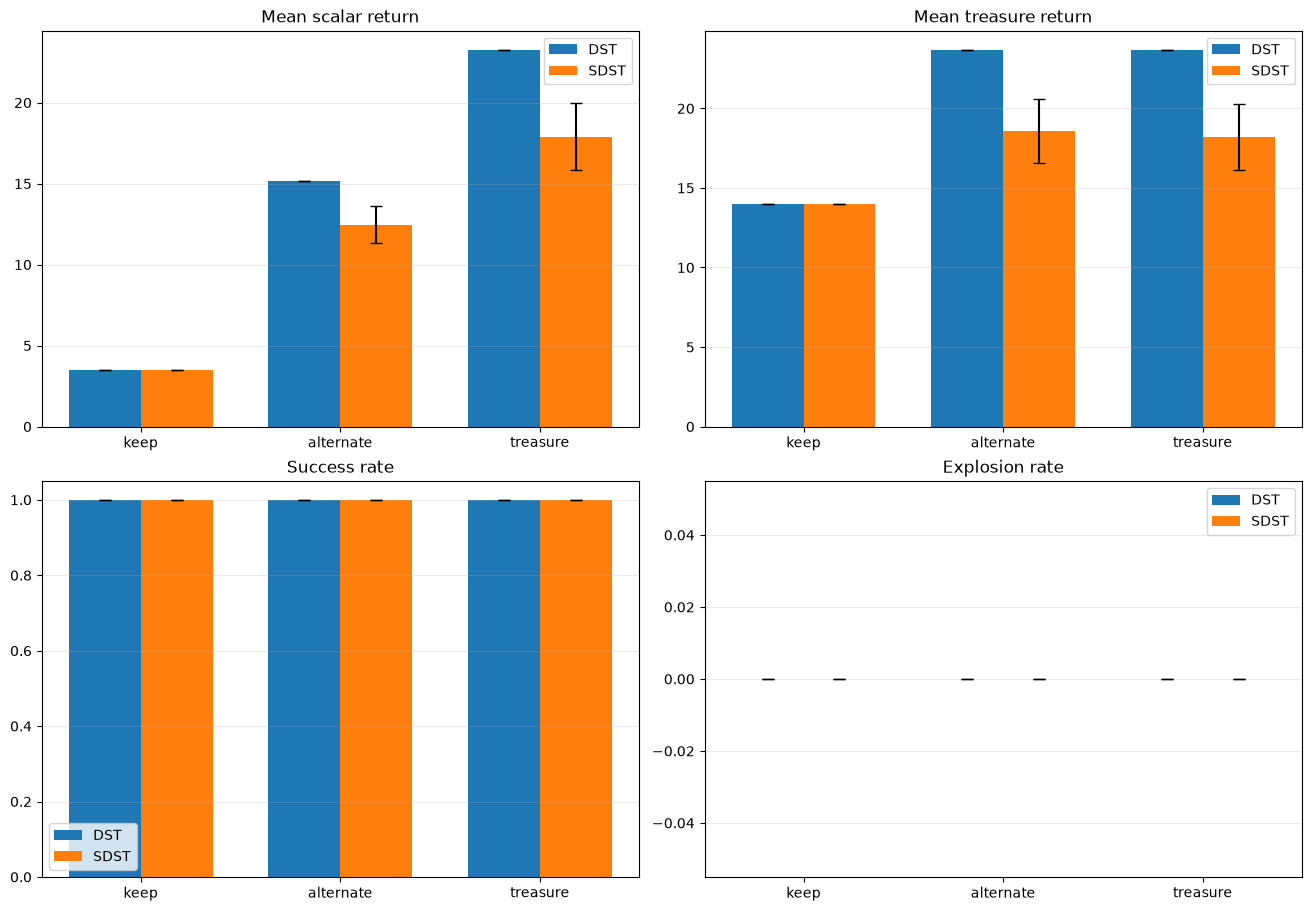

In [14]:
def grouped_values(rows, metric):
    grouped = defaultdict(list)
    for row in rows:
        grouped[(row["profile"], row["environment"])].append(float(row[metric]))
    return grouped

metrics = (
    ("mean_return_scalar", "Mean scalar return"),
    ("mean_return_treasure", "Mean treasure return"),
    ("success_rate", "Success rate"),
    ("explosion_rate", "Explosion rate"),
)
profiles = list(PROFILES)
environments = list(ENVIRONMENTS)
x = np.arange(len(profiles))
width = 0.36
fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
for axis, (metric, title) in zip(axes.flat, metrics):
    grouped = grouped_values(summary_rows, metric)
    for environment_index, environment_name in enumerate(environments):
        values = [grouped[(profile, environment_name)] for profile in profiles]
        means = [np.mean(item) for item in values]
        standard_deviations = [np.std(item) for item in values]
        offset = (environment_index - 0.5) * width
        axis.bar(
            x + offset, means, width, yerr=standard_deviations,
            capsize=4, label=environment_name,
        )
    axis.set_title(title)
    axis.set_xticks(x, profiles)
    axis.grid(axis="y", alpha=0.25)
    axis.legend()

figure_path = EXPERIMENT_ROOT / "final_metrics.png"
fig.savefig(figure_path, dpi=180)
plt.show()

### Compare learned P values

Comparison of the final P values at the **initial state**, for each action (later, we will see a comparison by comparing the P values of the states only)

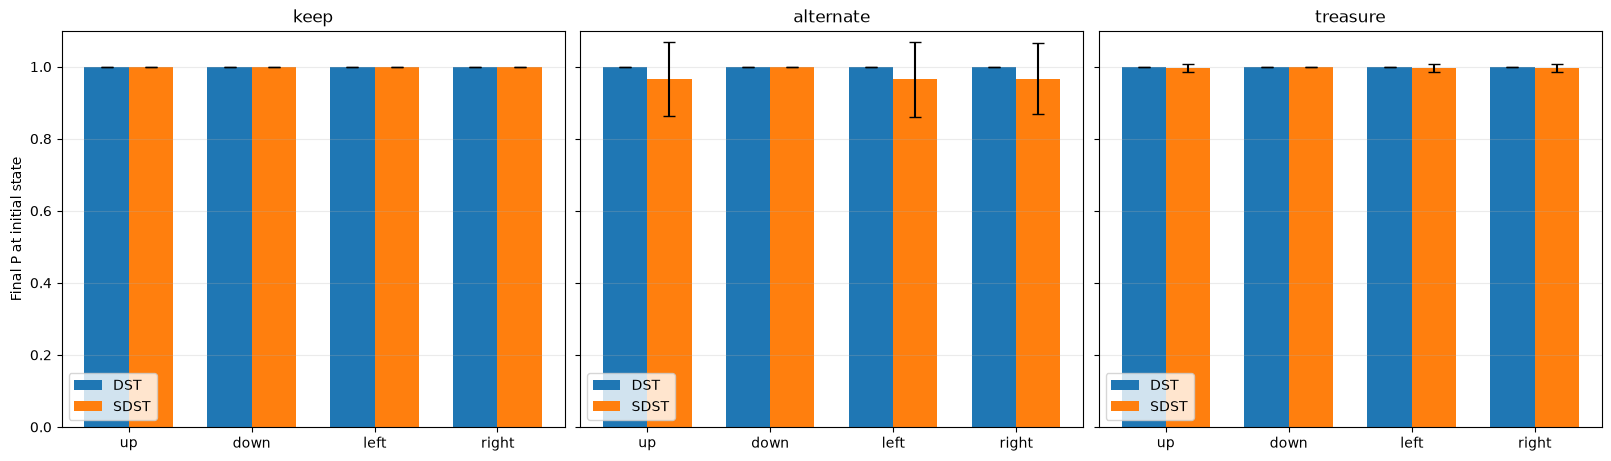

In [15]:
p_grouped = defaultdict(list)
for row in initial_p_rows:
    p_grouped[(row["profile"], row["environment"], row["action_name"])].append(
        float(row["p_value"])
    )

action_names = [ENVIRONMENTS["DST"].environment.action_names[index] for index in range(4)]
action_x = np.arange(len(action_names))
fig, axes = plt.subplots(1, len(profiles), figsize=(16, 4.5), sharey=True, constrained_layout=True)
for axis, profile in zip(axes, profiles):
    for environment_index, environment_name in enumerate(environments):
        values = [p_grouped[(profile, environment_name, action)] for action in action_names]
        means = [np.mean(item) for item in values]
        standard_deviations = [np.std(item) for item in values]
        offset = (environment_index - 0.5) * width
        axis.bar(
            action_x + offset, means, width, yerr=standard_deviations,
            capsize=4, label=environment_name,
        )
    axis.set_title(profile)
    axis.set_xticks(action_x, action_names)
    axis.set_ylim(0, 1.1)
    axis.grid(axis="y", alpha=0.25)
    axis.legend()
axes[0].set_ylabel("Final P at initial state")

p_figure_path = EXPERIMENT_ROOT / "initial_state_p_values.png"
fig.savefig(p_figure_path, dpi=180)
plt.show()

Info files:
- summary.csv: final metrics and final preferences for all 60 runs
- validation_history.csv: checkpoint metrics before each automated preference choice
- initial_state_p_values.csv: final initial-state P values used in the comparison figure
- all_p_values.csv: final P, Q, objective Q, and visit values for every visited state-action pair
- final_metrics.png: DST and SDST final-metric comparison
- initial_state_p_values.png: side-by-side DST and SDST initial-state P comparison

Each environment__profile__run directory contains:
- model.pkl: complete final TabularModel
- run_config.json: exact run configuration
- profile.json: automated preference choices and matched seed
- feedback_history.json and feedback_log.csv: applied preference changes
- validation_history.json: checkpoint validation metrics
- evaluation_summary.json: final evaluation metrics
- learning_returns.csv: per-episode scalar and objective returns
- p_values.csv: that run's complete visited-state P table
- training_segments/: versioned models and statistics between feedback moments

### TODO:
state-wise P value, show a heatmap of both environments to see how P values change between both environments for each state